# Appendix C: encoder and decoder circuits

The gates for Figures S1 and S2 are listed directly below. Compute each
isometry from its circuit and print every matrix entry to 8 decimal places.
The row and column orders agree with `AppendixC_fidelity.ipynb` and the
supplied encoder/decoder matrix data.

The final section copies the encoder and decoder matrices from the
GitHub repository and prints the maximum absolute entrywise differences.


In [1]:
import numpy as np
from numpy import pi, sqrt, arcsin, arctan
from qiskit import QuantumCircuit
from qiskit.circuit.library import XGate, ZGate, RYGate
from qiskit.quantum_info import Operator

np.set_printoptions(precision=8, suppress=True, linewidth=240, threshold=np.inf)


## Encoder (Figure S1)

Wires $q_0,q_1,q_2,q_3$ are $P\!\to\!R,I_3,I_2,I_1$.
Only $q_0$ carries an input; $q_1,q_2,q_3$ start in $|0\rangle$.
Qiskit orders basis states as $|q_3q_2q_1q_0\rangle$.
Thus the first two columns give $V_{\mathrm{enc}}$ of size $16\times2$,
with rows $|I_1I_2I_3R\rangle$ and columns $|P\rangle$.


In [2]:
encoder = QuantumCircuit(4, name="encoder")
encoder.swap(0, 1)
encoder.x(2)
encoder.ry(-pi/2, 3)
encoder.cx(3, 2)
encoder.ry(2*arcsin(sqrt(2/3)), 0)
encoder.cswap(0, 3, 1)
encoder.ry(-2*arctan(sqrt(3)-sqrt(2)), 0)
encoder.cswap(0, 3, 2)
encoder.ry(2*arctan(sqrt(3)-sqrt(2)), 0)


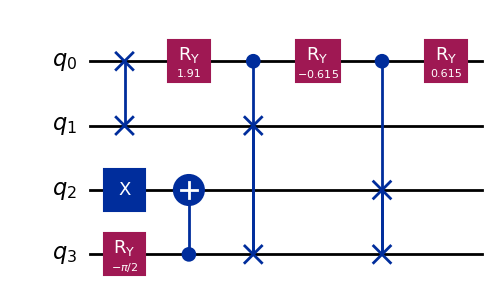

In [3]:
encoder.draw(output="mpl", fold=80)


In [4]:
Venc = Operator(encoder).data[:, :2]
print("Venc (16 x 2), rows |I1 I2 I3 R>, columns |P>:")
print(np.real_if_close(Venc))


Venc (16 x 2), rows |I1 I2 I3 R>, columns |P>:
[[ 0.          0.        ]
 [ 0.          0.        ]
 [-0.          0.        ]
 [-0.57735027  0.        ]
 [ 0.5         0.        ]
 [ 0.28867513  0.        ]
 [ 0.          0.5       ]
 [ 0.         -0.28867513]
 [-0.5         0.        ]
 [ 0.28867513  0.        ]
 [ 0.         -0.5       ]
 [ 0.         -0.28867513]
 [ 0.         -0.        ]
 [ 0.          0.57735027]
 [ 0.          0.        ]
 [ 0.          0.        ]]


## Decoder (Figure S2)

Wires $q_0,q_1,q_2,q_3,q_4$ are $O_3,O_2,O_1,R,F$ at the input;
at the output they are $A_4,A_3,A_2,A_1,F$.
For each controlled gate, the wire list gives the controls first and target
last; the rightmost bit of `ctrl_state` belongs to the first control wire.

$F$ starts in $|0\rangle$, so the first 16 columns give
$V_{\mathrm{dec}}$ of size $32\times16$.
Rows are $|FA_1A_2A_3A_4\rangle$ and columns are $|RO_1O_2O_3\rangle$.


In [5]:
decoder = QuantumCircuit(5, name="decoder")

# Input phases and routing.
decoder.append(ZGate().control(3, ctrl_state="001"), [1, 2, 3, 0])
decoder.append(ZGate().control(3, ctrl_state="010"), [1, 2, 3, 0])
decoder.append(ZGate().control(3, ctrl_state="010"), [0, 2, 3, 1])
decoder.append(XGate().control(1, ctrl_state="0"), [2, 0])  # q2=0: flip q0
decoder.cx(1, 2)
decoder.swap(1, 3)
decoder.ccx(0, 2, 3)
decoder.append(XGate().control(2, ctrl_state="01"), [2, 3, 0])  # q2=1, q3=0: flip q0
decoder.ccx(0, 1, 2)
decoder.ccx(0, 2, 1)
decoder.append(XGate().control(1, ctrl_state="0"), [1, 0])  # q1=0: flip q0
decoder.append(XGate().control(3, ctrl_state="100"), [0, 1, 2, 4])  # q0=0, q1=0, q2=1: flip q4
decoder.append(XGate().control(3, ctrl_state="000"), [0, 1, 4, 2])  # q0=0, q1=0, q4=0: flip q2
decoder.append(XGate().control(2, ctrl_state="00"), [1, 2, 0])  # q1=0, q2=0: flip q0

# Rotation core.
decoder.append(RYGate(pi).control(2, ctrl_state="01"), [1, 2, 0])
decoder.append(RYGate(-3*pi/2).control(2, ctrl_state="10"), [0, 1, 2])
decoder.append(RYGate(2*arctan(3-2*sqrt(2))).control(2, ctrl_state="01"), [1, 2, 0])
decoder.append(RYGate(-2*pi+2*arctan(sqrt(6))).control(2, ctrl_state="11"), [1, 2, 0])
decoder.append(RYGate(2*arctan(sqrt(7))).control(2, ctrl_state="11"), [0, 2, 1])
decoder.append(RYGate(-2*pi+2*arctan(2/sqrt(3))).control(2, ctrl_state="11"), [1, 2, 0])
decoder.append(RYGate(-2*arctan(sqrt(2))).control(2, ctrl_state="10"), [0, 1, 2])
decoder.append(RYGate(4*pi/3).control(2, ctrl_state="01"), [1, 2, 0])
decoder.append(RYGate(2*pi-2*arctan(2/sqrt(3))).control(2, ctrl_state="01"), [0, 1, 2])
decoder.append(RYGate(2*pi-2*arctan(sqrt(14)/2)).control(2, ctrl_state="00"), [1, 2, 0])
decoder.append(RYGate(2*pi-2*arctan(sqrt(6))).control(2, ctrl_state="01"), [0, 1, 2])
decoder.append(RYGate(-2*arctan(3-2*sqrt(2))).control(2, ctrl_state="11"), [0, 2, 1])

# Output phases and routing.
decoder.append(ZGate().control(4, ctrl_state="0000"), [0, 1, 3, 4, 2])
decoder.append(ZGate().control(2, ctrl_state="00"), [1, 2, 3])
decoder.append(ZGate().control(2, ctrl_state="11"), [1, 3, 0])
decoder.append(ZGate().control(2, ctrl_state="00"), [0, 1, 2])
decoder.swap(3, 4)
decoder.append(XGate().control(3, ctrl_state="010"), [0, 2, 3, 1])  # q0=0, q2=1, q3=0: flip q1
decoder.append(XGate().control(2, ctrl_state="00"), [1, 3, 4])  # q1=0, q3=0: flip q4
decoder.append(XGate().control(3, ctrl_state="100"), [0, 1, 4, 3])  # q0=0, q1=0, q4=1: flip q3
decoder.append(XGate().control(3, ctrl_state="010"), [0, 2, 3, 1])  # q0=0, q2=1, q3=0: flip q1
decoder.append(XGate().control(4, ctrl_state="0010"), [1, 2, 3, 4, 0])  # q1=0, q2=1, q3=0, q4=0: flip q0
decoder.append(XGate().control(3, ctrl_state="001"), [0, 1, 2, 4])  # q0=1, q1=0, q2=0: flip q4


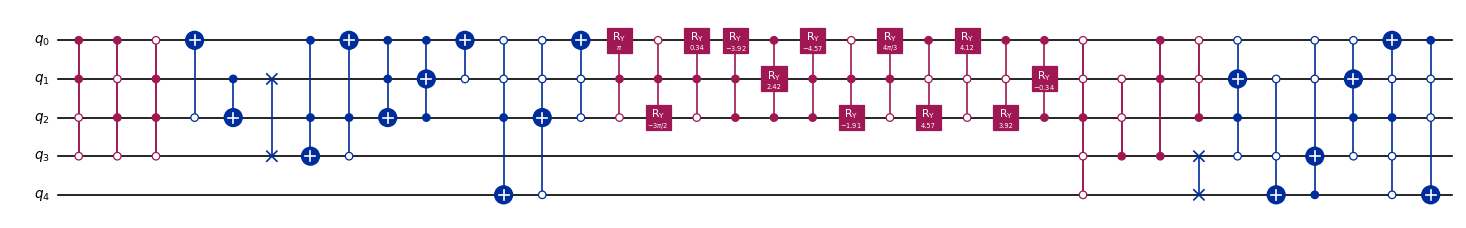

In [6]:
decoder.draw(output="mpl", fold=110, scale=0.6)


In [7]:
Vdec = Operator(decoder).data[:, :16]
print("Vdec (32 x 16), rows |F A1 A2 A3 A4>, columns |R O1 O2 O3>:")
print(np.real_if_close(Vdec))


Vdec (32 x 16), rows |F A1 A2 A3 A4>, columns |R O1 O2 O3>:
[[-0.         -0.         -0.          0.23570226 -0.          0.23570226 -0.47140452  0.         -0.          0.          0.          0.40824829  0.         -0.40824829  0.         -0.        ]
 [-0.         -0.33333333  0.16666667 -0.          0.16666667 -0.         -0.          0.          0.         -0.         -0.28867513  0.          0.28867513  0.         -0.          0.        ]
 [-0.          0.         -0.28867513  0.          0.28867513 -0.         -0.          0.          0.         -0.80473785 -0.30473785  0.         -0.30473785 -0.          0.         -0.        ]
 [ 0.         -0.          0.5        -0.         -0.5         0.          0.         -0.         -0.         -0.57735027  0.28867513  0.          0.28867513  0.         -0.          0.        ]
 [ 0.          0.          0.         -0.09763107 -0.         -0.09763107 -0.80473785  0.          0.         -0.         -0.         -0.40824829 -0.          0

## Compare with the GitHub encoder and decoder

The reference matrices below are copied from
[`parallel_encoder_decoder_isometries.ipynb`](https://github.com/jyzhau/Unitary-Purification/blob/da177f5dc99798cae799ad1b5828e6064a539f2c/parallel_encoder_decoder_isometries.ipynb).
Only the array names are changed to `encoder_github` and `decoder_github`.
The row and column orders are the same as those used above.
The differences use the original complex-valued circuit matrices.


In [8]:
s2, s3, s6 = np.sqrt(2), np.sqrt(3), np.sqrt(6)

encoder_github = np.array([
    [0, 0],
    [0, 0],
    [0, 0],
    [-s3/3, 0],
    [1/2, 0],
    [s3/6, 0],
    [0, 1/2],
    [0, -s3/6],
    [-1/2, 0],
    [s3/6, 0],
    [0, -1/2],
    [0, -s3/6],
    [0, 0],
    [0, s3/3],
    [0, 0],
    [0, 0],
], dtype=complex)

# Sparse matrix entries for the raw decoder.  Unlisted entries are zero.
decoder_github = np.zeros((32, 16), dtype=complex)
decoder_entries = [
    ( 0,  3, s2/6),
    ( 0,  5, s2/6),
    ( 0,  6, -s2/3),
    ( 0, 11, s6/6),
    ( 0, 13, -s6/6),
    ( 1,  1, -1/3),
    ( 1,  2, 1/6),
    ( 1,  4, 1/6),
    ( 1, 10, -s3/6),
    ( 1, 12, s3/6),
    ( 2,  2, -s3/6),
    ( 2,  4, s3/6),
    ( 2,  9, -s2/3 - 1/3),
    ( 2, 10, 1/6 - s2/3),
    ( 2, 12, 1/6 - s2/3),
    ( 3,  2, 1/2),
    ( 3,  4, -1/2),
    ( 3,  9, -s3/3),
    ( 3, 10, s3/6),
    ( 3, 12, s3/6),
    ( 4,  3, -1/3 + s2/6),
    ( 4,  5, -1/3 + s2/6),
    ( 4,  6, -s2/3 - 1/3),
    ( 4, 11, -s6/6),
    ( 4, 13, s6/6),
    ( 5,  0, 1),
    ( 6,  3, -s6/6),
    ( 6,  5, s6/6),
    ( 6, 11, -1/3 - s2/6),
    ( 6, 13, -1/3 - s2/6),
    ( 6, 14, -1/3 + s2/3),
    ( 7,  1, 1/3 - s2/3),
    ( 7,  2, -s2/3 - 1/6),
    ( 7,  4, -s2/3 - 1/6),
    ( 7, 10, -s3/6),
    ( 7, 12, s3/6),
    (12,  8, -1),
    (17,  3, 1/6),
    (17,  5, 1/6),
    (17,  6, -1/3),
    (17, 11, s3/6),
    (17, 13, -s3/6),
    (18,  3, s3/6),
    (18,  5, -s3/6),
    (18, 11, 1/6 - s2/3),
    (18, 13, 1/6 - s2/3),
    (18, 14, -s2/3 - 1/3),
    (19,  3, 1/2),
    (19,  5, -1/2),
    (19, 11, -s3/6),
    (19, 13, -s3/6),
    (19, 14, s3/3),
    (20,  7, -1),
    (21,  1, 1/3 + s2/3),
    (21,  2, 1/3 - s2/6),
    (21,  4, 1/3 - s2/6),
    (21, 10, -s6/6),
    (21, 12, s6/6),
    (22, 15, -1),
    (23,  3, -s2/3 - 1/6),
    (23,  5, -s2/3 - 1/6),
    (23,  6, 1/3 - s2/3),
    (23, 11, s3/6),
    (23, 13, -s3/6),
    (24,  1, -s2/3),
    (24,  2, s2/6),
    (24,  4, s2/6),
    (24, 10, -s6/6),
    (24, 12, s6/6),
    (28,  2, s6/6),
    (28,  4, -s6/6),
    (28,  9, -1/3 + s2/3),
    (28, 10, -1/3 - s2/6),
    (28, 12, -1/3 - s2/6),
]
for row, col, value in decoder_entries:
    decoder_github[row, col] = value

# The arrays above are the parallel encoder and decoder data.


In [9]:
print("Encoder max abs difference:", np.max(np.abs(Venc - encoder_github)))
print("Decoder max abs difference:", np.max(np.abs(Vdec - decoder_github)))


Encoder max abs difference: 2.7755575615628914e-16
Decoder max abs difference: 1.2040198628456839e-14
